# 04 — Decision Tree and Random Forest
**Member 4.** Train and tune both tree-based models on the original (unscaled)
features, compare them, and analyse feature importance and interpretability.
Trees are invariant to monotonic feature scaling, so no `StandardScaler` is used.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.tree import plot_tree, export_text
from sklearn.inspection import permutation_importance
from common import *
from models import build_pipeline, display_name, GRIDS

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160, "display.max_columns", 40)
X_train, X_test, y_train, y_test = get_split()
del X_test, y_test

## 1. Decision Tree
Grid: split criterion, maximum depth, minimum samples per leaf, cost-complexity
pruning (`ccp_alpha`) and class weighting.

In [2]:
dt_grid = GRIDS["dtree"]
print(dt_grid)
dt_gs = tune(build_pipeline("dtree"), dt_grid, X_train, y_train)
print("best params:", dt_gs.best_params_)
print(f"best CV F1: {dt_gs.best_score_:.4f}")

{'clf__criterion': ['gini', 'entropy'], 'clf__max_depth': [2, 3, 4, 5, 6, 8, None], 'clf__min_samples_leaf': [1, 2, 5, 10], 'clf__ccp_alpha': [0.0, 0.002, 0.005, 0.01, 0.02], 'clf__class_weight': [None, 'balanced']}


best params: {'clf__ccp_alpha': 0.0, 'clf__class_weight': 'balanced', 'clf__criterion': 'gini', 'clf__max_depth': 5, 'clf__min_samples_leaf': 5}
best CV F1: 0.9378


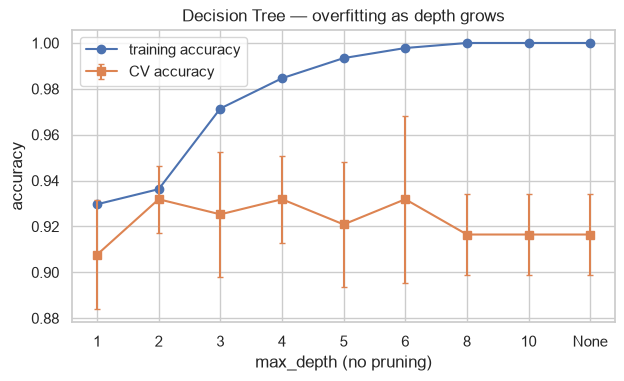

,max_depth,train_accuracy,cv_accuracy,cv_accuracy_std,cv_f1
0,1,0.9297,0.9077,0.0237,0.8721
1,2,0.9363,0.9319,0.0146,0.9092
2,3,0.9714,0.9253,0.0273,0.9002
3,4,0.9846,0.9319,0.0189,0.9104
4,5,0.9934,0.9209,0.0273,0.8964
5,6,0.9978,0.9319,0.0364,0.9113
6,8,1.0000,0.9165,0.0179,0.8906
7,10,1.0000,0.9165,0.0179,0.8906
8,None,1.0000,0.9165,0.0179,0.8906


In [3]:
depth_rows = []
for d in [1, 2, 3, 4, 5, 6, 8, 10, None]:
    p = {**dt_gs.best_params_, "clf__max_depth": d, "clf__ccp_alpha": 0.0, "clf__min_samples_leaf": 1}
    pipe = build_pipeline("dtree", p)
    row = cv_evaluate(pipe, X_train, y_train, name="DT", max_depth=str(d))
    row["train_accuracy"] = pipe.fit(X_train, y_train).score(X_train, y_train)
    depth_rows.append(row)
dr = pd.DataFrame(depth_rows)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(dr["max_depth"], dr["train_accuracy"], "o-", label="training accuracy")
ax.errorbar(dr["max_depth"], dr["cv_accuracy"], yerr=dr["cv_accuracy_std"], marker="s", capsize=2, label="CV accuracy")
ax.set_xlabel("max_depth (no pruning)"); ax.set_ylabel("accuracy"); ax.legend()
ax.set_title("Decision Tree — overfitting as depth grows")
savefig(fig, "04_dt_depth_curve"); plt.show()
dr[["max_depth", "train_accuracy", "cv_accuracy", "cv_accuracy_std", "cv_f1"]].round(4)

Training accuracy reaches 100 % for deep unpruned trees while CV accuracy stalls
around 92–94 %: a single tree overfits easily and its CV scores vary a lot between
folds (high variance) — the motivation for Random Forest.

depth: 5  leaves: 13


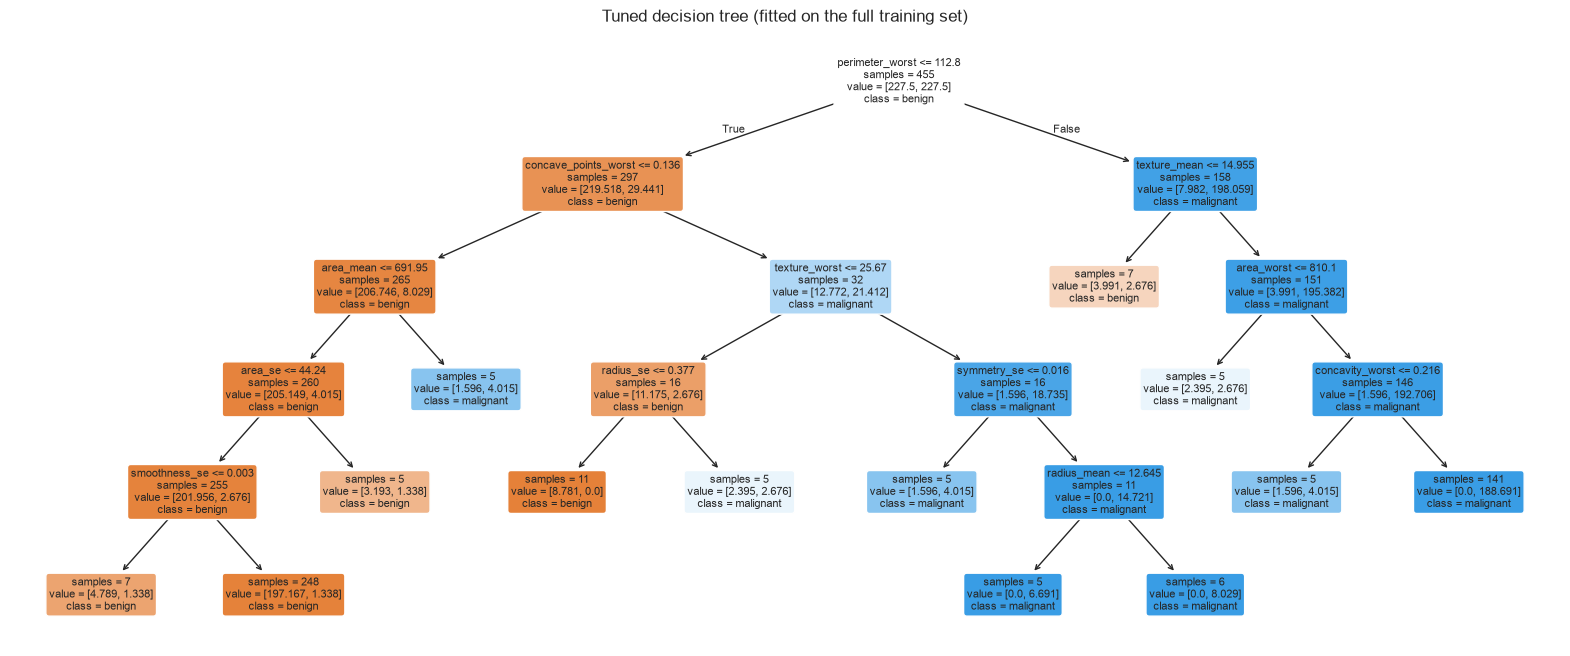

In [4]:
best_dt = dt_gs.best_estimator_.named_steps["clf"]
print("depth:", best_dt.get_depth(), " leaves:", best_dt.get_n_leaves())
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(best_dt, feature_names=FEATURE_NAMES, class_names=CLASS_NAMES, filled=True, rounded=True,
          fontsize=8, ax=ax, impurity=False, proportion=False)
ax.set_title("Tuned decision tree (fitted on the full training set)")
savefig(fig, "04_decision_tree"); plt.show()

In [5]:
print(export_text(best_dt, feature_names=FEATURE_NAMES, decimals=3))

|--- perimeter_worst <= 112.800
|   |--- concave_points_worst <= 0.136
|   |   |--- area_mean <= 691.950
|   |   |   |--- area_se <= 44.240
|   |   |   |   |--- smoothness_se <= 0.003
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- smoothness_se >  0.003
|   |   |   |   |   |--- class: 0
|   |   |   |--- area_se >  44.240
|   |   |   |   |--- class: 0
|   |   |--- area_mean >  691.950
|   |   |   |--- class: 1
|   |--- concave_points_worst >  0.136
|   |   |--- texture_worst <= 25.670
|   |   |   |--- radius_se <= 0.377
|   |   |   |   |--- class: 0
|   |   |   |--- radius_se >  0.377
|   |   |   |   |--- class: 1
|   |   |--- texture_worst >  25.670
|   |   |   |--- symmetry_se <= 0.016
|   |   |   |   |--- class: 1
|   |   |   |--- symmetry_se >  0.016
|   |   |   |   |--- radius_mean <= 12.645
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- radius_mean >  12.645
|   |   |   |   |   |--- class: 1
|--- perimeter_worst >  112.800
|   |--- texture_mean <= 14.955
|   |   |-

The tree is directly readable as a set of if–then rules on a handful of features —
the most interpretable model in the project.

## 2. Random Forest
Grid: number of trees, features considered per split, depth, minimum leaf size and
class weighting.

In [6]:
rf_grid = GRIDS["rf"]
print(rf_grid)
rf_gs = tune(build_pipeline("rf"), rf_grid, X_train, y_train)
print("best params:", rf_gs.best_params_)
print(f"best CV F1: {rf_gs.best_score_:.4f}")

{'clf__n_estimators': [200, 500], 'clf__max_features': ['sqrt', 'log2', 0.5], 'clf__max_depth': [None, 5, 10], 'clf__min_samples_leaf': [1, 2, 4], 'clf__class_weight': [None, 'balanced']}


best params: {'clf__class_weight': None, 'clf__max_depth': None, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 200}
best CV F1: 0.9587


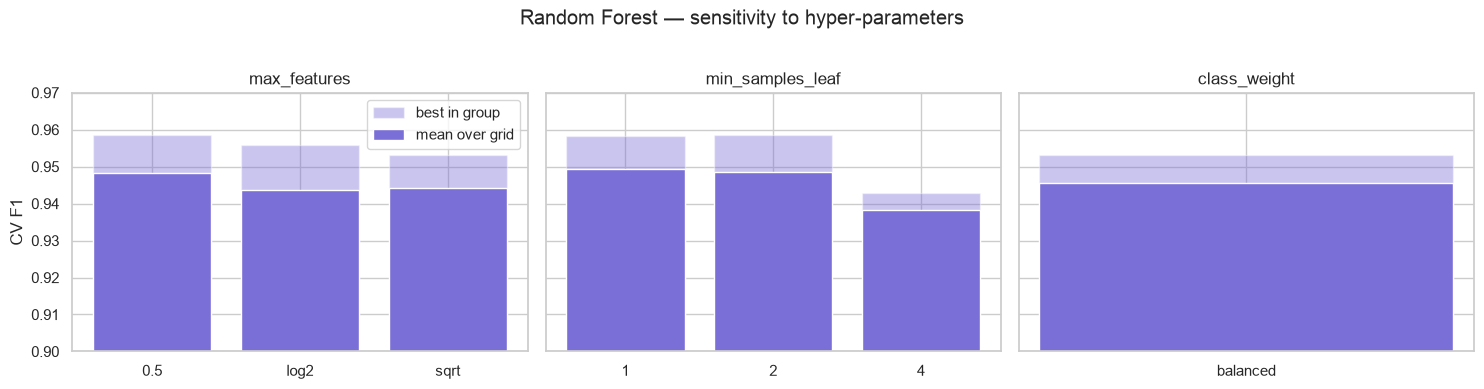

In [7]:
r = pd.DataFrame(rf_gs.cv_results_)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, prm in zip(axes, ["param_clf__max_features", "param_clf__min_samples_leaf", "param_clf__class_weight"]):
    g = r.assign(v=r[prm].astype(str)).groupby("v")["mean_test_f1"].agg(["mean", "max"])
    ax.bar(g.index, g["max"], color="#7A6FD6", alpha=.4, label="best in group")
    ax.bar(g.index, g["mean"], color="#7A6FD6", label="mean over grid")
    ax.set_title(prm.replace("param_clf__", "")); ax.set_ylim(0.9, 0.97)
axes[0].set_ylabel("CV F1"); axes[0].legend()
fig.suptitle("Random Forest — sensitivity to hyper-parameters", y=1.02); fig.tight_layout()
savefig(fig, "04_rf_hyperparams"); plt.show()

Random Forest is robust: almost every configuration in the grid lands within ~1–2
F1 points of the best, unlike the single tree.

## 3. Comparison

In [8]:
rows = [best_cv_row(dt_gs, display_name("dtree"), key="dtree", feature_set="all 30"),
        best_cv_row(rf_gs, display_name("rf"), key="rf", feature_set="all 30")]
save_rows(rows, "cv_04_trees.csv")
save_best_params("dtree", dt_gs.best_params_)
save_best_params("rf", rf_gs.best_params_)
summarize(rows)

,model,key,feature_set,accuracy,precision,recall,specificity,f1,roc_auc
0,Decision Tree,dtree,all 30,0.9538 ± 0.0224,0.9487 ± 0.0459,0.9294 ± 0.0399,0.9684 ± 0.0302,0.9378 ± 0.0297,0.9745 ± 0.0151
1,Random Forest,rf,all 30,0.9692 ± 0.0189,0.9662 ± 0.0396,0.9529 ± 0.0353,0.9789 ± 0.0258,0.9587 ± 0.0249,0.9848 ± 0.0103


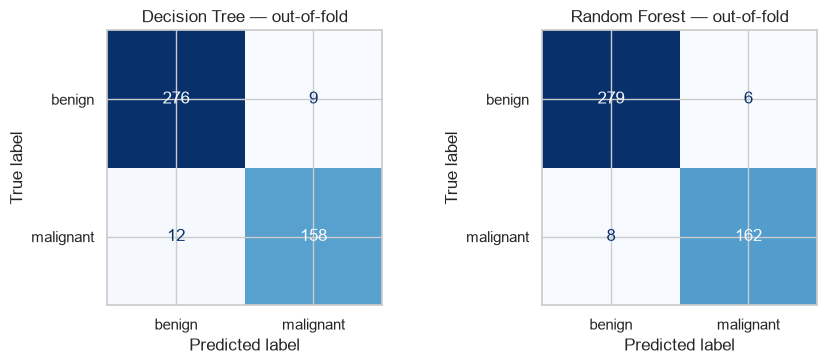

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (key, gs) in zip(axes, [("dtree", dt_gs), ("rf", rf_gs)]):
    pred = cross_val_predict(gs.best_estimator_, X_train, y_train, cv=get_cv())
    ConfusionMatrixDisplay.from_predictions(y_train, pred, display_labels=CLASS_NAMES, cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(f"{display_name(key)} — out-of-fold")
fig.tight_layout(); savefig(fig, "04_confusion"); plt.show()

## 4. Feature importance
Two views for the Random Forest:
* **Impurity (MDI) importance** — fast, but biased and split arbitrarily between
  correlated features (radius/perimeter/area share credit).
* **Permutation importance** — drop in F1 when a feature is shuffled. To avoid using
  the test set, it is computed on each CV validation fold (model fitted on the other
  four folds) and averaged.

In [10]:
rf = rf_gs.best_estimator_
mdi = pd.Series(rf.named_steps["clf"].feature_importances_, index=FEATURE_NAMES)

perm = []
for tr, va in get_cv().split(X_train, y_train):
    m = build_pipeline("rf", rf_gs.best_params_).fit(X_train.iloc[tr], y_train.iloc[tr])
    pi = permutation_importance(m, X_train.iloc[va], y_train.iloc[va], scoring="f1", n_repeats=20,
                                random_state=RANDOM_STATE, n_jobs=-1)
    perm.append(pi.importances_mean)
perm = pd.Series(np.mean(perm, axis=0), index=FEATURE_NAMES)
dt_imp = pd.Series(best_dt.feature_importances_, index=FEATURE_NAMES)

imp = pd.DataFrame({"rf_mdi": mdi, "rf_permutation": perm, "dt_importance": dt_imp}).sort_values("rf_mdi", ascending=False)
imp.to_csv(RESULTS_DIR / "feature_importance_trees.csv")
imp.head(15).round(4)

,rf_mdi,rf_permutation,dt_importance
perimeter_worst,0.2528,0.0094,0.7788
radius_worst,0.1739,0.0184,0.0000
concave_points_worst,0.1415,0.0343,0.0994
concave_points_mean,0.1337,0.0072,0.0000
area_worst,0.1174,0.0075,0.0103
texture_worst,0.0228,0.0199,0.0425
texture_mean,0.0199,0.0177,0.0210
perimeter_mean,0.0126,0.0000,0.0000
area_mean,0.0121,0.0080,0.0258
concavity_worst,0.0116,0.0056,0.0043


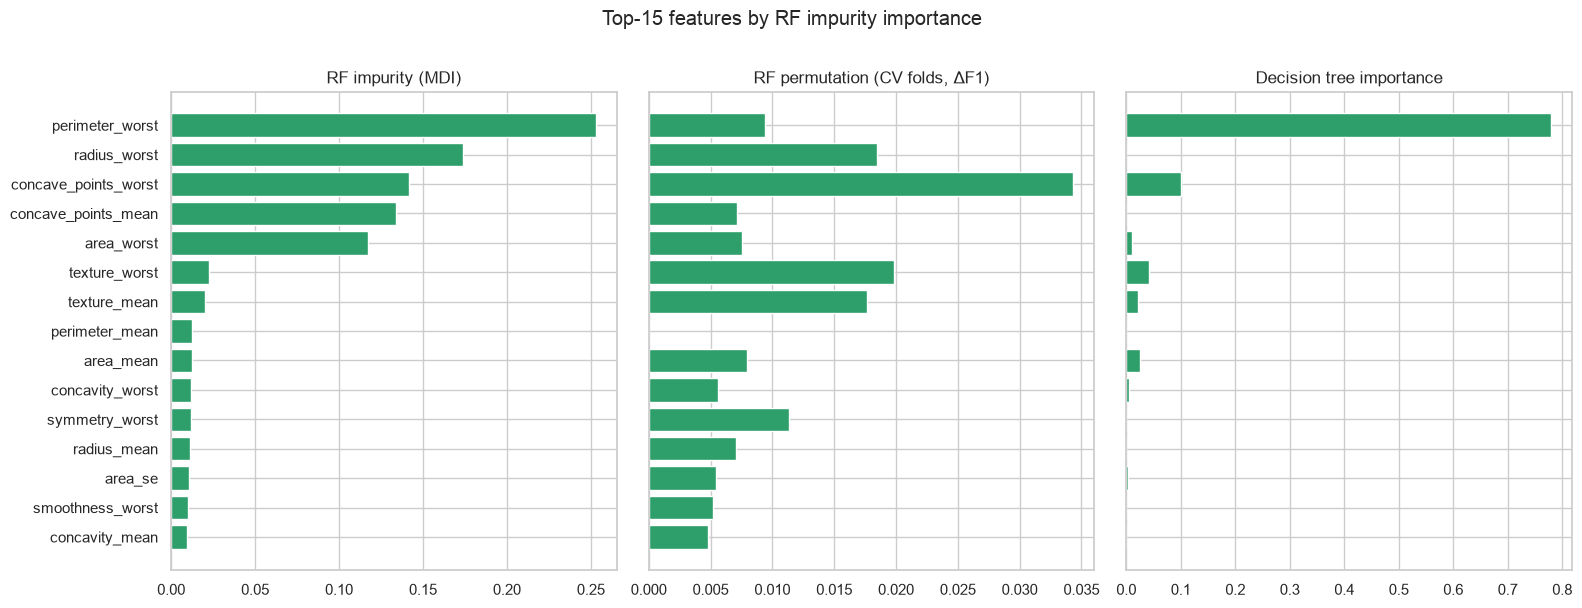

In [11]:
top = imp.head(15).index[::-1]
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
for ax, col, title in zip(axes, imp.columns, ["RF impurity (MDI)", "RF permutation (CV folds, ΔF1)", "Decision tree importance"]):
    ax.barh(top, imp.loc[top, col], color="#2E9E6B"); ax.set_title(title)
fig.suptitle("Top-15 features by RF impurity importance", y=1.01); fig.tight_layout()
savefig(fig, "04_feature_importance"); plt.show()

**Interpretation.** All three views put the "worst" size and concavity measurements on
top (`perimeter_worst`, `radius_worst`, `concave_points_worst`, `area_worst`,
`concave_points_mean`). The single tree uses `perimeter_worst` for almost all of its
splitting power (≈ 78 %), while the forest spreads the credit across the correlated
size features. Permutation importance tells the same story from another angle: shuffling
`perimeter_worst` alone barely hurts the forest (ΔF1 ≈ 0.01) because
`radius_worst`/`area_worst` carry the same information. This is a direct consequence
of the multicollinearity found in notebook 01. Permutation importance also
ranks **texture** (`texture_worst`, `texture_mean`) much higher than MDI does: texture is
the main *non-redundant* signal, since no other feature can stand in for it.

**Interpretability trade-off.** The single tree is fully transparent (a few rules)
but less accurate and unstable; the forest is more accurate and stable but can only
be explained through aggregate importances.